In [14]:
#Candidate Name: Utkarsh Singh
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# Load the data
cheese_df = pd.read_csv('C:/Users/utkar/Downloads/cheese_data.csv')
weather_df = pd.read_csv('C:/Users/utkar/Downloads/canada_weather.csv')

In [16]:
# data pipeline: Clean and preprocess both datasets
# Handle missing values in cheese data
cheese_df['MoisturePercent'] = cheese_df['MoisturePercent'].fillna(cheese_df['MoisturePercent'].mean())

In [17]:
# Clean temperature data in weather data and handle missing values
#extracts numeric temperature values from strings using a regular expression
#converts them to floats and fills any missing values with the mean of each temperature column.
temp_cols = [col for col in weather_df.columns if 'Avg. high' in col]
for col in temp_cols:
    weather_df[col] = weather_df[col].str.extract(r'([-+]?\d*\.\d+|\d+)').astype(float)
weather_df[temp_cols] = weather_df[temp_cols].fillna(weather_df[temp_cols].mean())

# Add province info to weather data
weather_df['Province'] = weather_df['Community'].str.split(', ').str[1]

# Merge datasets
cheese_df = cheese_df.merge(weather_df[['Province', 'July(Avg. high °C (°F))']], 
                           left_on='ManufacturerProvCode', 
                           right_on='Province', 
                           how='left')

In [18]:
# Filter for valid provinces
valid_provinces = ['NB', 'ON', 'BC', 'AB', 'NS', 'PE', 'MB', 'NL', 'QC']
cheese_df = cheese_df[cheese_df['ManufacturerProvCode'].isin(valid_provinces)]

# Analysis Approach: Group by province and calculate averages
prov_group = cheese_df.groupby('ManufacturerProvCode').agg({
    'MoisturePercent': 'mean',
    'July(Avg. high °C (°F))': 'mean'
}).dropna()

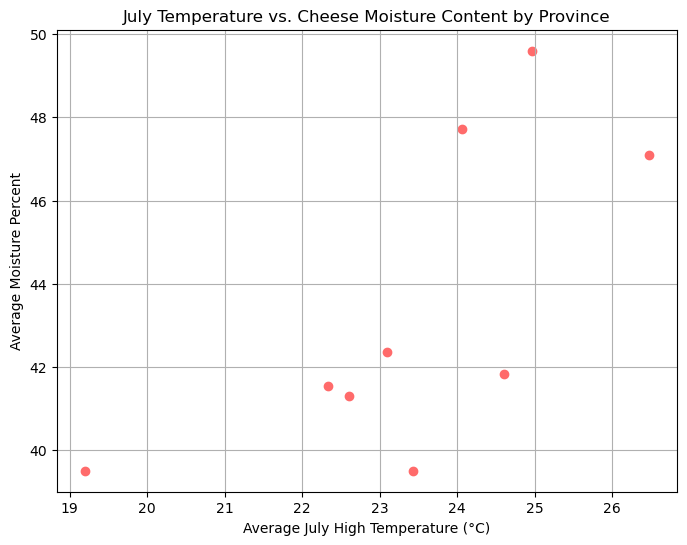

In [19]:
# Visualization 1: Scatter plot of July temperature vs. Moisture Percent
plt.figure(figsize=(8, 6))
plt.scatter(prov_group['July(Avg. high °C (°F))'], prov_group['MoisturePercent'], color='#FF6B6B')
plt.xlabel('Average July High Temperature (°C)')
plt.ylabel('Average Moisture Percent')
plt.title('July Temperature vs. Cheese Moisture Content by Province')
plt.grid(True)
plt.show()

###### Above scatterplot shows avg July High Temp vs Cheese Moisture. 
Here, it has a weak positive trend
Provinces like ON and BC with warmer summer temp tend to produce cheese with high moisture (40-50%) 
leading to fresh and soft cheese.
Cooler provinces like Newfoundland and Labrador produce having temp (19 to 21 degree celsius)
produce cheese with low moisture (20-40%) leading to firmer aged type cheese
Hence, warmer temp may encourage shorter aging process retaining more moisture
While cooler climate support longer aging for drier cheeses

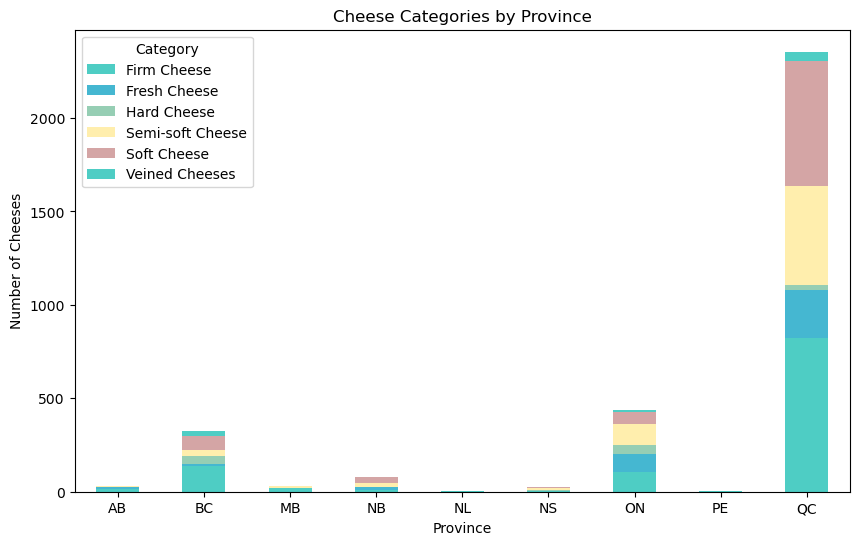

In [20]:
# Visualization 2: Stacked bar plot of cheese categories by province
category_counts = cheese_df.groupby(['ManufacturerProvCode', 'CategoryTypeEn']).size().unstack(fill_value=0)
category_counts.plot(kind='bar', stacked=True, figsize=(10, 6), color=['#4ECDC4', '#45B7D1', '#96CEB4', '#FFEEAD', '#D4A5A5'])
plt.xlabel('Province')
plt.ylabel('Number of Cheeses')
plt.title('Cheese Categories by Province')
plt.legend(title='Category')
plt.xticks(rotation=0)
plt.show()

###### From the above "Cheese Categories by Province" stacked bar chart
warmer/milder climates like Quebec (QC) and British Columbia (BC) show high diversity (over 2000 and 300–400 cheeses), 
suggesting varied weather supports multiple cheese types.
Cooler climates like Newfoundland (NL) and Prince Edward Island (PE) have minimal production (near 0),
indicating weather constraints.
Moderate climates like Ontario (ON) and Alberta (AB) (200–500 cheeses) balance fresh and aged varieties, 
linking weather to cheese diversity.